In [1]:
%pip install gensim

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
    --------------------------------------- 0.5/24.4 MB 4.8 MB/s eta 0:00:05
   -- ------------------------------------- 1.6/24.4 MB 4.9 MB/s eta 0:00:05
   ---- ----------------------------------- 2.9/24.4 MB 5.5 MB/s eta 0:00:04
   ------ --------------------------------- 4.2/24.4 MB 5.7 MB/s eta 0:00:04
   --------- ------------------------------ 6.0/24.4 MB 6.5 MB/s eta 0:00:03
   ------------- -------------------------- 8.1/24.4 MB 7.2 MB/s eta 0:00:03
   ----------------- ---------------------- 10.7/24.4 MB 8.0 MB/s eta 0:00:02
   ---------------------- ----------------- 13.9/24.4 MB 9.0 MB/s eta 0:00:02
   --------------------------- ------------ 17.0/24.4 MB 9.7 MB/s eta 0:00:01
   -------------------------------- ------- 19.9/24.4 MB 10.1 MB/s eta 0:00:01
   ------------------------------------- -- 23.1/24.4 MB 10.6 MB/s eta 0:00:0

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.3.109 requires numpy<=2.1.1,>=1.23.0, but you have numpy 2.4.6 which is incompatible.

[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import re
import html

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [ ]:
# text = html.unescape(text.lower())
# text = re.sub(r"<.*?>", " ", text)
# words = re.findall(r"\b[a-z]+\b", text)

# text = str(text).lower()
# text = re.sub(r"http\S+|www\S+|@\w+", " ", text)
# text = re.sub(r"[^a-z\s]", " ", text)
# words = text.split()

# sentences = re.split(r'[.!?]+', text)
# words = re.findall(r'[a-z]+', sen)

In [2]:
df = pd.read_csv('IMDB Dataset.csv')

df['sentiment'] = df['sentiment'].map({
    'positive' : 1,
    'negative' : 0
})

X = df['review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42, 
    stratify=y
)

In [5]:
# tokenize each review
stop_words = set(ENGLISH_STOP_WORDS) - {'no', 'not', 'nor', 'never'}

def preprocess(text):
    text = html.unescape(text.lower())

    text = re.sub(r"<.*?>", " ", text)

    words = re.findall(r"\b[a-z]+\b", text)

    filtered_words = []

    for word in words:
        if word not in stop_words:
            filtered_words.append(word)

    return filtered_words

#train_sentences is an array of arrays
#every inner array is an array of tokenized words
train_sentences = []
for sentence in X_train:
    train_sentences.append(preprocess(sentence))

test_sentences = []
for sentence in X_test:
    test_sentences.append(preprocess(sentence))

In [6]:
word2vec = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=10
)

In [11]:
#now i have a 100 size vector for every word
#now find the avg of all words for every review

def get_vector(words):
    vectors = []

    for word in words:
        if word in word2vec.wv:
            vectors.append(word2vec.wv[word])

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)


X_train_vec = []
for sentence in train_sentences:
    X_train_vec.append(get_vector(sentence))

X_train_vec = np.array(X_train_vec)

X_test_vec = []
for sentence in test_sentences:
    X_test_vec.append(get_vector(sentence))

X_test_vec = np.array(X_test_vec)

In [12]:
model = Sequential([
    Input(shape=(100,)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid'),
])

In [14]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [15]:
history = model.fit(
    X_train_vec,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8311 - loss: 0.3840 - val_accuracy: 0.8643 - val_loss: 0.3174
Epoch 2/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8581 - loss: 0.3311 - val_accuracy: 0.8655 - val_loss: 0.3090
Epoch 3/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8630 - loss: 0.3252 - val_accuracy: 0.8645 - val_loss: 0.3053
Epoch 4/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8656 - loss: 0.3207 - val_accuracy: 0.8685 - val_loss: 0.3073
Epoch 5/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8703 - loss: 0.3153 - val_accuracy: 0.8690 - val_loss: 0.3040
Epoch 6/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8691 - loss: 0.3151 - val_accuracy: 0.8680 - val_loss: 0.3105
Epoch 7/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8718 - loss: 0.3096 - val_accuracy: 0.8735 - val_loss: 0.3011
Epoch 8/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8725 - loss: 0.3079 - val_accuracy: 0.

In [17]:
test_loss, test_accuracy = model.evaluate(X_test_vec, y_test)

print("Test loss: ", test_loss)
print("Test accuracy: ", test_accuracy*100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8713 - loss: 0.3056
Test loss:  0.30562835931777954
Test accuracy:  87.12999820709229 %


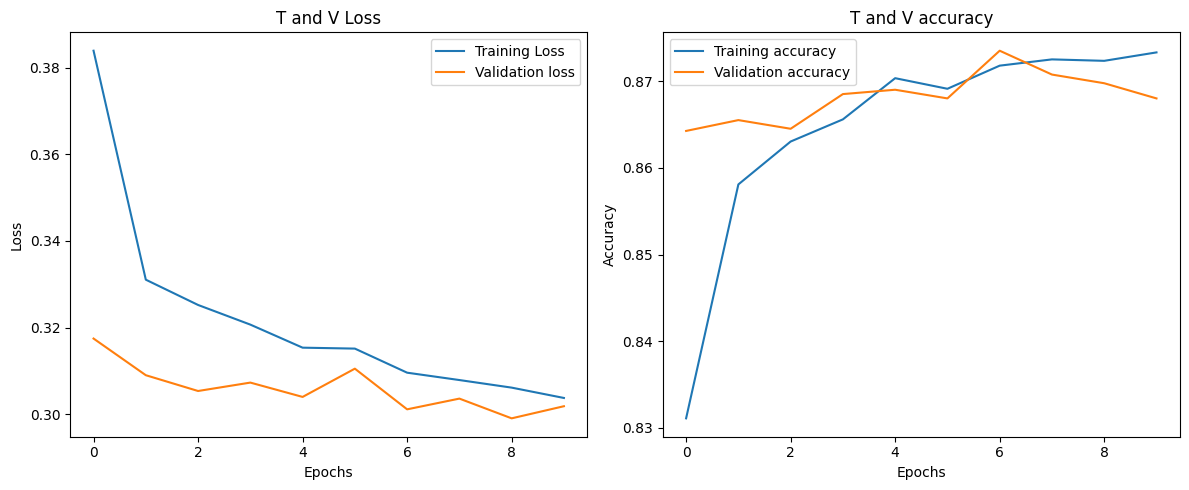

In [18]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation loss")
plt.title("T and V Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = "Training accuracy")
plt.plot(history.history['val_accuracy'], label = "Validation accuracy")
plt.title("T and V accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()